# Excercise 02 - Introduction to Python (OpenCV) - Image Visualization

Deadline for the submission: 17.11.2026 at 23.59. Upload a single ZIP file to Stud.IP. Make sure that it is clear, which file presents the solution for which excercise.

# Introduction to OpenCV

### OpenCV (Open Source Computer Vision Library) is a popular C++/Python library for image and video processing and broader computer-vision tasks. It offers hundreds of optimized functions, from simple filtering to modern object detection and tracking, and runs on desktops, mobile devices, and embedded systems.

- Image processing basics: crop, resize, rotate, color conversions (BGR/RGB/HSV), histograms, smoothing/sharpening.

- Edges, shapes, and features: Canny edge detection, contours, Hough lines/circles, and feature descriptors.

- Object & face detection: classical methods (Haar cascades, HOG) and DNN support to run modern detectors like YOLO.

- Video I/O & tracking: read/write camera streams and files; single- and multi-object trackers.

- Optical character recognition pipelines: preprocessing to boost text recognition quality.

- Segmentation: global/adaptive thresholding (we will do this later).


## Use Case 1: Image IO and Color Space

1.1 Describe the difference between BGR, RGB and grayscale color space!  
  
1.2 Fill in the missing code (___) in the Jupyter Notebook to visualize scene.jpg in each color space from task 1.1!

### 1.1 BGR vs RGB vs Grayscale
| | BGR | RGB | Grayscale |
|---|---|---|---|
| Channels | 3 | 3 | 1 |
| Channel order | Blue, Green, Red | Red, Green, Blue | single intensity |
| Array shape | (H, W, 3) | (H, W, 3) | (H, W) |
| Used by | OpenCV (`cv2.imread` default) | Matplotlib, PIL, most other libs | Edge detection, thresholding, etc. |
| Information | Full color | Full color | Color discarded, only brightness kept |
- BGR vs RGB: same data, same color model, only the channel order is swapped (channel 0 and channel 2 exchanged). OpenCV historically uses BGR for legacy camera and file-format reasons (OpenCV docs, cvtColor).
- Consequence: displaying a BGR array with plt.imshow treats channel 0 as red, so red and blue are swapped. That is why img_bgr in your third plot looks off-color. This is intended in the exercise.
- Grayscale: one channel per pixel. OpenCV computes it as Y = 0.299·R + 0.587·G + 0.114·B (same source as above). Green dominates because human vision is most sensitive to it. Storage is 1/3 of a color image.

### 1.2 Code

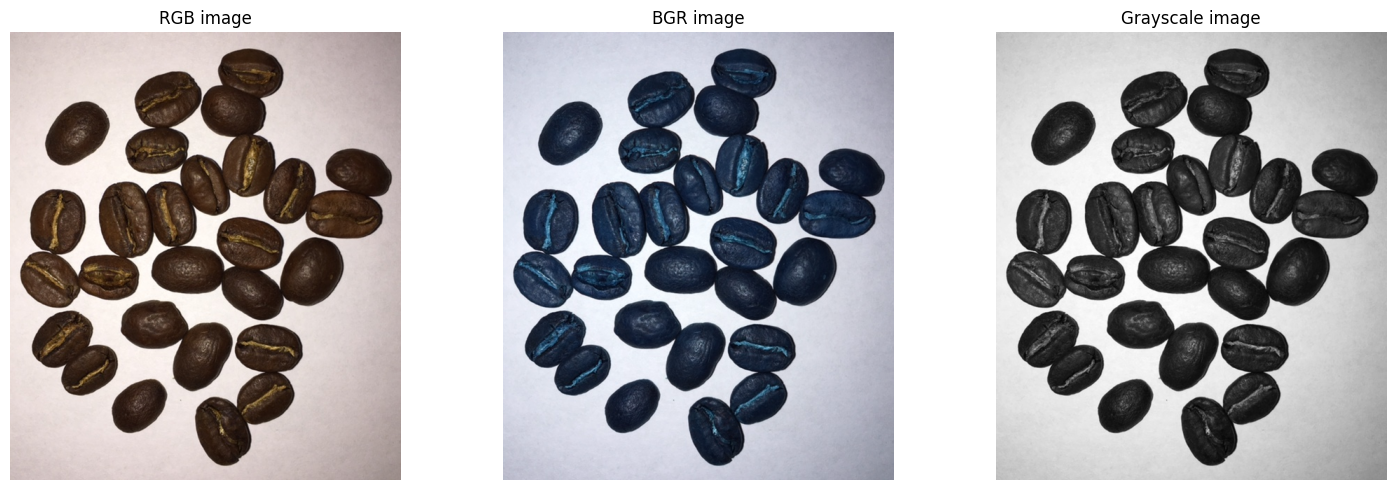

In [1]:
import cv2 as cv2
import matplotlib.pyplot as plt
img_path = "./data/scene.jpg"
img_bgr = cv2.imread(img_path)
assert img_bgr is not None, f"Please place an image at {img_path}"

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(img_rgb)
plt.title("RGB image")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(img_bgr)
plt.title("BGR image")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(img_gray, cmap="gray")
plt.title("Grayscale image")
plt.axis("off")
plt.tight_layout()
plt.show()


## Use Case 2: Basic Image Operations

2.1 Fill in the missing code (___) in the Jupyter Notebook (Use Case 2) to recreate the given image (Figure 1: output.png)
  
<figure>
<img src="data/output.png" width="800">
<figcaption> Figure 1: Different OpenCV functions </figcaption>
</figure>

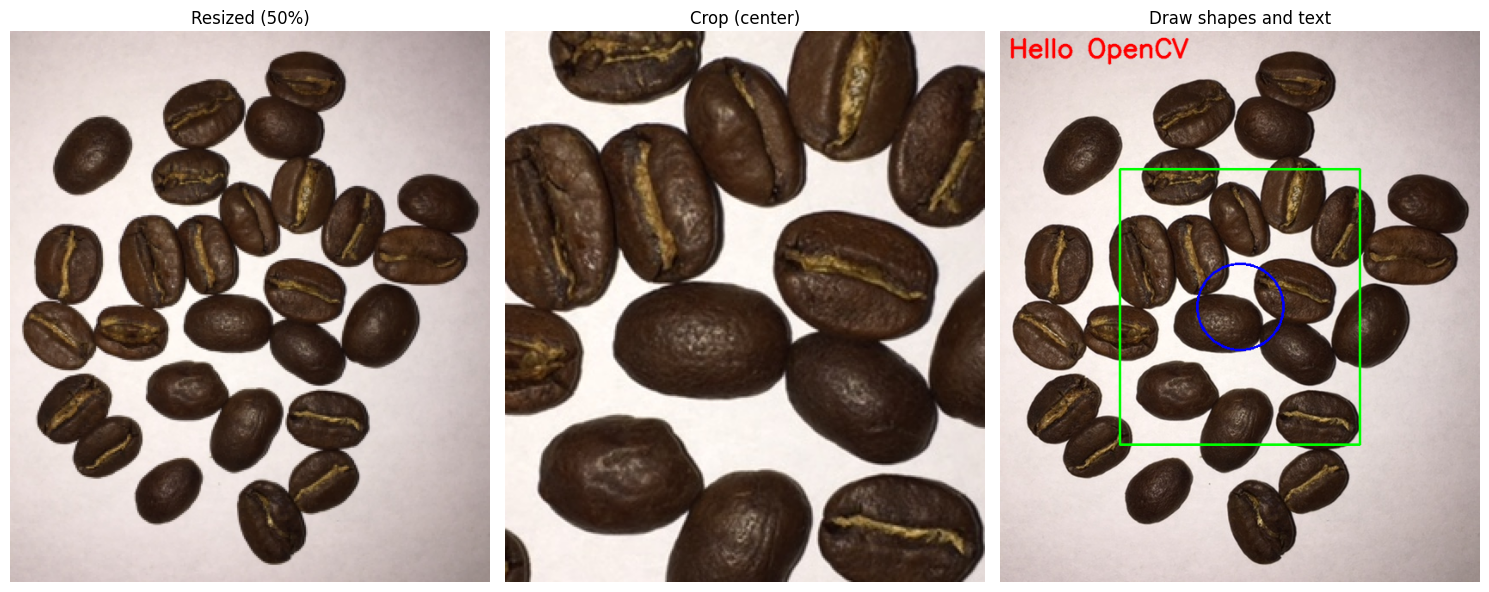

In [2]:
import cv2 as cv2
import matplotlib.pyplot as plt

h, w = img_bgr.shape[:2]


# Resize to half size
half = cv2.resize(img_bgr, (int(w/2),int(h/2)))

# # Crop a centered region (quarter size)
y1 = int(h/4)
y2 = int(h* 3/4)
x1 = int(w/4)
x2 = int(w * 3/4)
crop = img_bgr[y1:y2, x1:x2]

# Draw a rectangle and a circle on a copy
drawn = img_bgr.copy()
cv2.rectangle(drawn, (x1,y1),(x2,y2), (0, 255, 0), thickness=2)
cv2.circle(drawn, (int(w/2),int(h/2)), radius=50, color=(255, 0, 0), thickness=2)
cv2.putText(drawn, "Hello OpenCV", (10,30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2, cv2.LINE_AA)

plt.figure(figsize=(15,6))
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(half, cv2.COLOR_BGR2RGB))
plt.title("Resized (50%)")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.title("Crop (center)")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
plt.title("Draw shapes and text")
plt.axis("off")
plt.tight_layout()
plt.show()

## Use Case 3: Video detection

3.1 Use a camera to create a live image or record a video with your Smartphone and try out the Code in this Chapter  
  
3.2 Understand the Code below, investigate the parameters and comment the code it  
  
3.3 Write a few sentences about the idea of the Code in this Chapter

In [4]:
# Press 'q' in the window to quit.
import cv2

source = "data/video.mp4" # Camera index (0 = default webcam). A string path = video file.
min_area = 800 # Minimum contour area in square pixels. Smaller blobs are treated as noise and ignore. Higher = fewer false boxes, but small objects are missed.
history = 300  # Number of recent frames the model uses to learn the background.
var_threshold = 16 # Squared Mahalanobis distance between a pixel and the background model above which the pixel is called foreground, lower = more sensetive, higher = stricter


cap = cv2.VideoCapture(source) # Opening webcam / file
if not cap.isOpened(): # Fallback if webcam is unavailable
    print("Webcam not available. Trying data/video.mp4...")
    cap = cv2.VideoCapture("data/video.mp4")

if not cap.isOpened():
    print("Could not open any video source. Please add data/video.mp4 or connect a webcam.")
else:
    # MOG2 models every pixel as a mixture of Gaussians and updates it every frame.
    # detectShadows=True: shadoes are labeled gray (127) instead of white (255).
    backsub = cv2.createBackgroundSubtractorMOG2(history=history, varThreshold=var_threshold, detectShadows=True)

    # 3x3 elliptical structuring element for the morphological operations below
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))

    while True:
        edok, frame = cap.read() # ok becomes False at end of file or camera error, otherwise it returns True
        if not ok:
            print("End of stream or cannot read frame.")
            break
        # 1) Compare the frame to the background model and update the model.
        # # Output: 0 = background, 127 = shadow, 255 = foreground.    
        fgmask = backsub.apply(frame)

        # 2) Opening (erode, then dilate): removes small white noise.
        fgmask = cv2.morphologyEx(fgmask, cv2.MORPH_OPEN, kernel, iterations=1)

        # 3) Closing (dilalte, then erode), 2 passes: fills small black holes inside objects so one object doesn't split into several blobs.
        fgmask = cv2.morphologyEx(fgmask, cv2.MORPH_CLOSE, kernel, iterations=2)

        # 4) Binarize at 200: only pure foreground (255) survives; shadows (127) become 0.
        _, fgmask_bin = cv2.threshold(fgmask, 200, 255, cv2.THRESH_BINARY)

        # 5) Find outlines of white blobs. RETR_EXTERNAL = outer contours only (no holes); CHAIN_APPROX_SIMPLE = score only corner points to save memory.
        contours, _ = cv2.findContours(fgmask_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        for c in contours:
            if cv2.contourArea(c) > min_area: # This ensures small blobs will be ignored
                x,y,w,h = cv2.boundingRect(c) # Smallest upright rectangle around blob
                cv2.rectangle(frame, (x,y), (x+w,y+h), (0,255,0), 2) # Green (BGR), 2 px

        cv2.imshow("Background Subtraction Detection (press q to quit)", frame) # Annotated video

        cv2.imshow("Foreground Mask", fgmask_bin) # Binary mask

        # Wait 1 ms for a key; mask to the lowest 8 bits for cross-platform compatibility
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release() # Free the camera/file
    cv2.destroyAllWindows() # Close all windows


End of stream or cannot read frame.


### 3.3 Explanation

The code detects moving objects with background subtraction. The algorithm (MOG2) learns what the static scene normally looks like by modeling each pixel as a mixture of Gaussian distributions over the last history frames. Any pixel that deviates strongly from this model marked as foreground, which gives a binary mask of what moved. Morphological opening and closing clean up oise and holes in hte mask, shadows are filtered out by thresholding, and the remaining blobs larger than minimum area are outlined with bounding boxes. This needs no training data and no neural network, and runs in real time on a CPU. It only works well with a static camera and fairly stable lighting. 

#### Example applications

1. **Traffic monitoring:** a fixed camera over a road counts passing vehicles. Each box marks a car, and the count of boxes crossing a virtual line gives traffic density. 

2. **Security and intrusion detection:** a camera watching a room, warehouse or door triggers an alert or starts recording when a person enters. minimum area keeps small disturbances like insects or dust from causing false alarms.